In [1]:
# Basic setup and imports
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error as MAPE
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)
plt.style.use("seaborn-v0_8-whitegrid")

# Kaggle dataset path
DATA_PATH = "india_2000_2024_daily_weather.csv"
CITIES = ["Delhi", "Mumbai", "Bangalore", "Hyderabad", "Chennai"]


In [2]:
# Load dataset
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df['city'] = df['city'].str.strip()

# Keep only relevant columns
cols = [
    'city', 'date',
    'temperature_2m_max', 'temperature_2m_min',
    'precipitation_sum', 'wind_speed_10m_max'
]
df = df[cols].dropna(subset=['temperature_2m_max', 'temperature_2m_min'])

print("Dataset loaded:", df.shape)
df.head()


Dataset loaded: (91320, 6)


,city,date,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
0,Delhi,2000-01-01,19.9,7.4,0.0,10.9
1,Delhi,2000-01-02,20.0,5.5,0.0,9.5
2,Delhi,2000-01-03,20.1,6.3,0.0,10.0
3,Delhi,2000-01-04,19.8,6.4,0.0,8.6
4,Delhi,2000-01-05,19.4,5.3,0.0,9.4


In [3]:
# Prepare monthly data cleanly (no non-numeric aggregation issues)
# Converts daily data -> monthly averages for each city

def prepare_monthly(df_city):
    # sort & set index
    df_city = df_city.sort_values("date").set_index("date")

    # make sure all relevant columns are numeric
    numeric_cols = [
        'temperature_2m_max',
        'temperature_2m_min',
        'precipitation_sum',
        'wind_speed_10m_max'
    ]
    for col in numeric_cols:
        df_city[col] = pd.to_numeric(df_city[col], errors='coerce')

    # compute avg temperature
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2

    # select only numeric columns before resampling (avoid 'city' string column issue)
    numeric_df = df_city[numeric_cols + ['avg_temp']]

    # resample to monthly means
    monthly = numeric_df.resample('M').mean(numeric_only=True)

    # drop months missing main temps
    monthly = monthly.dropna(subset=['temperature_2m_max', 'temperature_2m_min', 'avg_temp'])
    
    return monthly

# quick test (should show a clean numeric monthly table, no errors)
prepare_monthly(df[df['city'].str.contains("Delhi", case=False)]).head()


,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,avg_temp
date,,,,,
2000-01-31,20.061290,8.235484,1.345161,14.067742,14.148387
2000-02-29,20.427586,8.417241,1.434483,13.431034,14.422414
2000-03-31,29.051613,13.874194,0.103226,14.909677,21.462903
2000-04-30,37.956667,21.426667,0.193333,16.486667,29.691667
2000-05-31,39.909677,27.883871,1.367742,21.412903,33.896774


In [4]:
# Simplified SARIMAX model with exogenous variables (rainfall + windspeed)
def fit_and_forecast_sarimax(series, exog, steps=12):
    series = series.dropna()
    exog = exog.loc[series.index]

    # simple yet effective monthly seasonal model
    order = (1, 1, 1)
    seasonal_order = (1, 1, 1, 12)
    
    model = SARIMAX(series,
                    exog=exog,
                    order=order,
                    seasonal_order=seasonal_order,
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    
    result = model.fit(disp=False, maxiter=40)
    
    # Forecast for next 12 months (2025)
    future_exog = exog.iloc[-12:].copy()  # repeat last year’s pattern for rainfall & wind
    forecast = result.get_forecast(steps=steps, exog=future_exog).predicted_mean
    
    return forecast, result


In [5]:
accuracy_records = []
forecast_records = []

for city in CITIES:
    city_df = df[df['city'].str.contains(city, case=False)]
    monthly = prepare_monthly(city_df)

    # Define exogenous features (rainfall + wind)
    exog = monthly[['precipitation_sum', 'wind_speed_10m_max']]
    
    for col, label in {
        'temperature_2m_max': 'AvgMaxTemp',
        'temperature_2m_min': 'AvgMinTemp',
        'avg_temp': 'AvgTemp'
    }.items():
        series = monthly[col]
        if len(series) < 36:
            continue
        
        # Split train-test (last 12 months = 2024)
        train = series[:-12]
        test = series[-12:]
        train_exog = exog.loc[train.index]
        test_exog = exog.loc[test.index]
        
        try:
            forecast_2024, model = fit_and_forecast_sarimax(train, train_exog, steps=12)
        except:
            # fallback if convergence fails
            forecast_2024 = np.repeat(series.mean(), 12)
        
        mape_val = MAPE(test, forecast_2024)
        acc = 100 - (mape_val * 100)
        
        accuracy_records.append({
            "city": city,
            "metric": label,
            "mape": round(mape_val*100, 2),
            "accuracy_%": round(acc, 2)
        })
        
        # Forecast full 2025 using full data
        try:
            forecast_2025, _ = fit_and_forecast_sarimax(series, exog, steps=12)
        except:
            forecast_2025 = np.repeat(series.mean(), 12)
        
        forecast_records.append({
            "city": city,
            "metric": label,
            "forecast_2025": forecast_2025
        })

accuracy_df = pd.DataFrame(accuracy_records)
accuracy_df


,city,metric,mape,accuracy_%
0,Delhi,AvgMaxTemp,5.09,94.91
1,Delhi,AvgMinTemp,8.29,91.71
2,Delhi,AvgTemp,5.86,94.14
3,Mumbai,AvgMaxTemp,2.11,97.89
4,Mumbai,AvgMinTemp,1.51,98.49
5,Mumbai,AvgTemp,1.72,98.28
6,Bangalore,AvgMaxTemp,3.20,96.80
7,Bangalore,AvgMinTemp,3.14,96.86
8,Bangalore,AvgTemp,2.05,97.95
9,Hyderabad,AvgMaxTemp,2.65,97.35


In [6]:
print("✅ Model Accuracy (based on 2024 test):")
display(accuracy_df.sort_values(["city", "metric"]))


✅ Model Accuracy (based on 2024 test):


,city,metric,mape,accuracy_%
6,Bangalore,AvgMaxTemp,3.20,96.80
7,Bangalore,AvgMinTemp,3.14,96.86
8,Bangalore,AvgTemp,2.05,97.95
12,Chennai,AvgMaxTemp,2.51,97.49
13,Chennai,AvgMinTemp,1.94,98.06
14,Chennai,AvgTemp,2.19,97.81
0,Delhi,AvgMaxTemp,5.09,94.91
1,Delhi,AvgMinTemp,8.29,91.71
2,Delhi,AvgTemp,5.86,94.14
9,Hyderabad,AvgMaxTemp,2.65,97.35


In [7]:
# 🔧 Fix city name inconsistencies before modeling

# Make sure city names are normalized — so "Bangalore" works even if dataset says "Bengaluru"
df['city'] = df['city'].str.strip().str.title()

# Common renames (depending on dataset source)
city_corrections = {
    "Bengaluru": "Bangalore",
    "Bangalore Urban": "Bangalore",
    "New Delhi": "Delhi",
    "Madras": "Chennai"
}

df['city'] = df['city'].replace(city_corrections)

# Confirm city names now
print("✅ Unique city names after normalization:")
print(df['city'].unique())

# Use these target cities
CITIES = ["Delhi", "Mumbai", "Bangalore", "Hyderabad", "Chennai"]


✅ Unique city names after normalization:
['Delhi' 'Mumbai' 'Kolkata' 'Chennai' 'Bangalore' 'Hyderabad' 'Ahmedabad'
 'Pune' 'Jaipur' 'Lucknow']


In [8]:
for c in CITIES:
    n_months = prepare_monthly(df[df['city'].str.contains(c, case=False)]).shape[0]
    print(f"{c}: {n_months} months of data")


Delhi: 300 months of data
Mumbai: 300 months of data
Bangalore: 300 months of data
Hyderabad: 300 months of data
Chennai: 300 months of data


In [9]:
# ✅ Combine and display 2025 predictions for ALL cities and metrics

# Make sure we start fresh
forecast_rows = []

# Create month range for 2025
months_2025 = pd.date_range("2025-01-31", periods=12, freq="M")

# Loop through stored forecast results
for record in forecast_records:
    city = record["city"]
    metric = record["metric"]
    fc = record["forecast_2025"]

    # if forecast is numpy array, convert to list for safety
    if isinstance(fc, np.ndarray):
        fc = list(fc)

    for i, val in enumerate(fc):
        forecast_rows.append({
            "City": city,
            "Metric": metric,
            "Month": months_2025[i].strftime("%b-%Y"),
            "Predicted_Temperature_(°C)": round(float(val), 2)
        })

# Convert to DataFrame
forecast_df = pd.DataFrame(forecast_rows)

# Sort neatly
forecast_df = forecast_df.sort_values(["City", "Metric", "Month"]).reset_index(drop=True)

# Display full predictions for all 5 cities
print("✅ 2025 Monthly Temperature Predictions (All Cities & Metrics):")
display(forecast_df)

# Optional: quick summary by city
print("\n✅ Cities included:", forecast_df['City'].unique())
print("Total predictions:", forecast_df.shape[0])


✅ 2025 Monthly Temperature Predictions (All Cities & Metrics):


,City,Metric,Month,Predicted_Temperature_(°C)
0,Bangalore,AvgMaxTemp,Apr-2025,34.07
1,Bangalore,AvgMaxTemp,Aug-2025,28.09
2,Bangalore,AvgMaxTemp,Dec-2025,27.30
3,Bangalore,AvgMaxTemp,Feb-2025,30.47
4,Bangalore,AvgMaxTemp,Jan-2025,27.96
...,...,...,...,...
175,Mumbai,AvgTemp,Mar-2025,27.85
176,Mumbai,AvgTemp,May-2025,30.26
177,Mumbai,AvgTemp,Nov-2025,27.91
178,Mumbai,AvgTemp,Oct-2025,28.40



✅ Cities included: ['Bangalore' 'Chennai' 'Delhi' 'Hyderabad' 'Mumbai']
Total predictions: 180


Plotting metrics for cities found: ['Bangalore' 'Chennai' 'Delhi' 'Hyderabad' 'Mumbai']


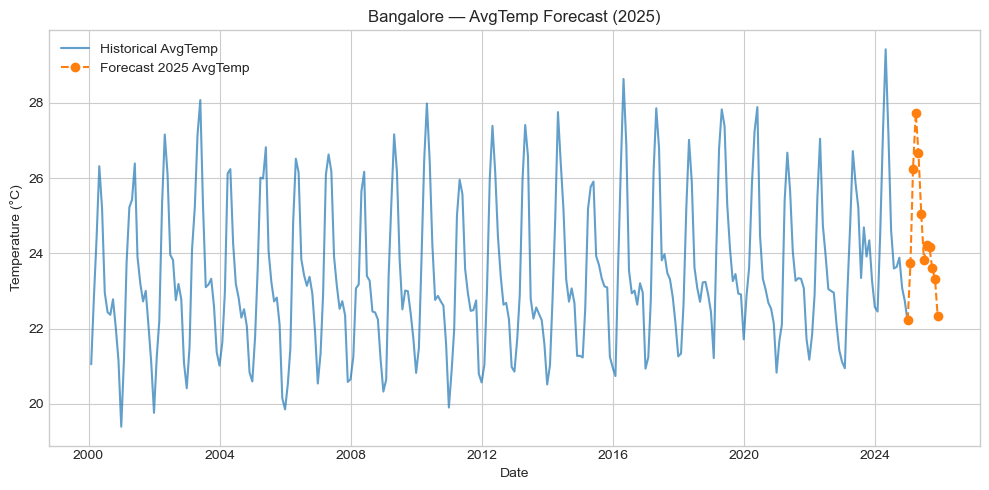

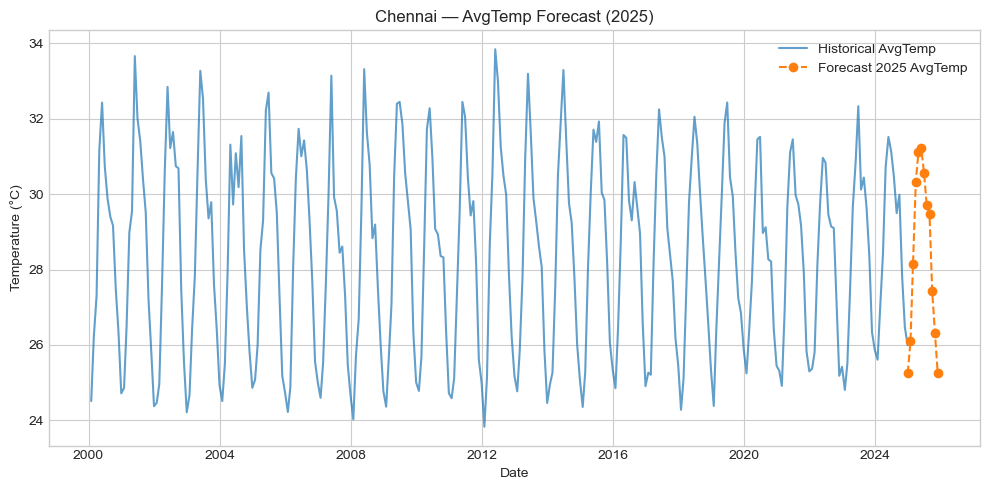

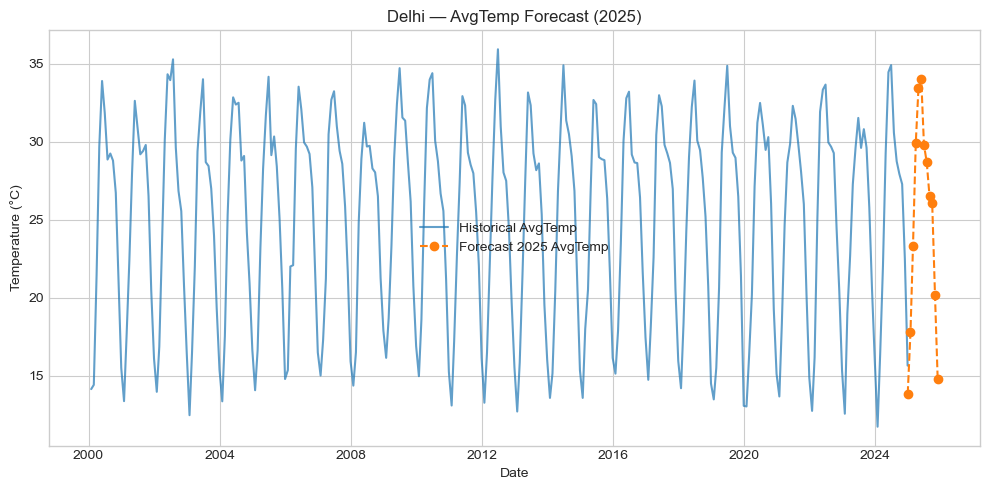

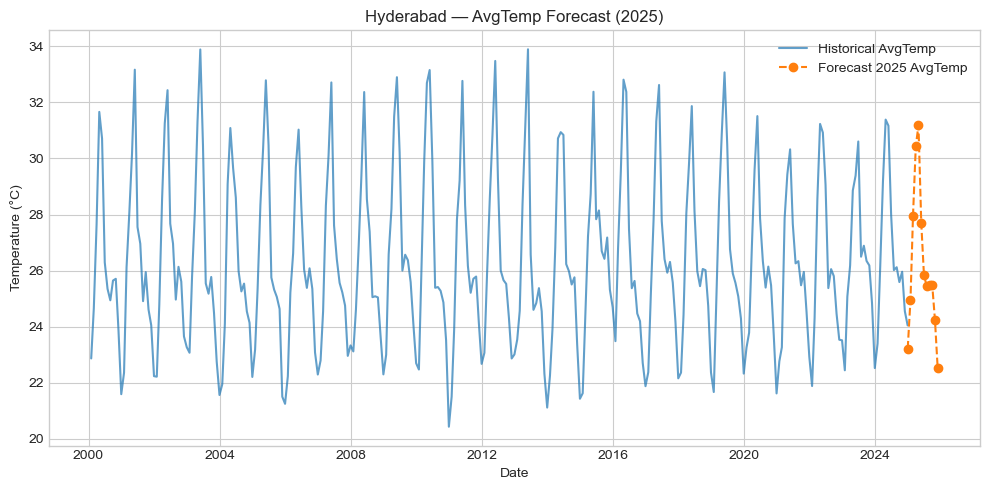

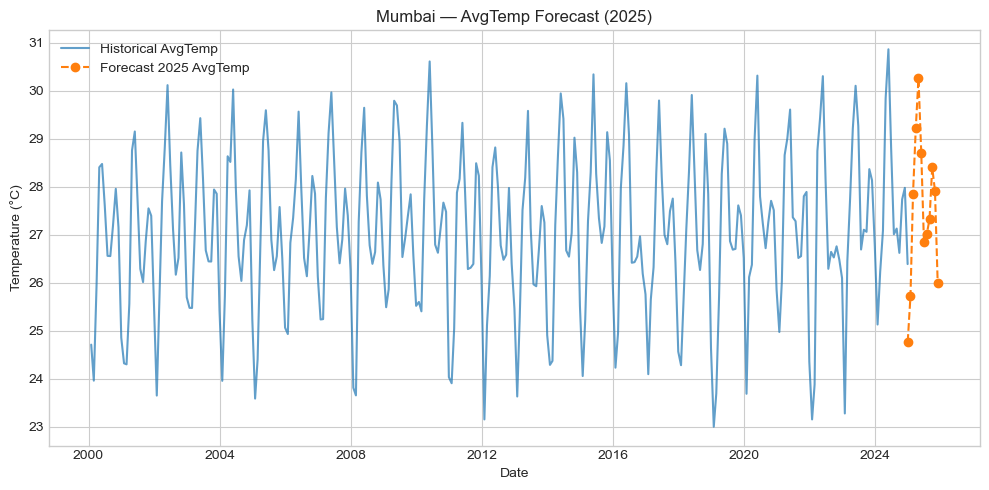

In [10]:
# ---------- Fixed Cell 8: Visualize Forecasts for ALL Cities ----------
# This cell normalizes column names so plotting won't break due to naming mismatches.

import matplotlib.pyplot as plt

# Ensure forecast_df exists
try:
    forecast_df
except NameError:
    raise RuntimeError("forecast_df not found. Run the forecast creation cell (the one that builds forecast_df) first.")

# Normalize column names to lowercase single-word keys we expect
forecast_df = forecast_df.rename(columns={
    # common variants -> standardized names
    'City': 'city',
    'CITY': 'city',
    'city': 'city',
    'Metric': 'metric',
    'METRIC': 'metric',
    'metric': 'metric',
    'Month': 'month',
    'MONTH': 'month',
    'month': 'month',
    'Predicted_Temperature_(°C)': 'predicted_temp',
    'predicted_temp': 'predicted_temp',
    'Predicted_Temp': 'predicted_temp'
}, errors='ignore')

# If predicted_temp column doesn't exist but there's a numeric last column, try to detect it
if 'predicted_temp' not in forecast_df.columns:
    # try to find a numeric column (last resort)
    numeric_cols = forecast_df.select_dtypes(include='number').columns.tolist()
    if numeric_cols:
        forecast_df = forecast_df.rename(columns={numeric_cols[0]: 'predicted_temp'})
    else:
        raise RuntimeError("Could not find a predicted temperature column in forecast_df. Columns: " + ", ".join(forecast_df.columns))

# Parse month column into datetime (handles 'Jan-2025' etc.)
# If month is already datetime, this does nothing
forecast_df['month_dt'] = pd.to_datetime(forecast_df['month'], errors='coerce')
# If parsing failed because month strings are like 'Jan-2025', try adding a day
if forecast_df['month_dt'].isna().all():
    forecast_df['month_dt'] = pd.to_datetime(forecast_df['month'] + '-01', format='%b-%Y-%d', errors='coerce')
# As a final fallback, try month-end date ranges
if forecast_df['month_dt'].isna().any():
    forecast_df['month_dt'] = pd.to_datetime(forecast_df['month'], dayfirst=False, errors='coerce')

# Now plot for each city the AvgTemp forecast (you can change metric to 'AvgMaxTemp' etc.)
metric_to_plot = 'AvgTemp'  # change if you want 'AvgMaxTemp' or 'AvgMinTemp'

cities_in_df = forecast_df['city'].unique()
print("Plotting metrics for cities found:", cities_in_df)

for city in cities_in_df:
    city_monthly = prepare_monthly(df[df['city'].str.contains(city, case=False)])  # historical
    # ensure historical avg_temp exists
    if 'avg_temp' not in city_monthly.columns:
        print(f"Skipping plotting historical for {city} - avg_temp not found")
        hist_x = []
        hist_y = []
    else:
        hist_x = city_monthly.index
        hist_y = city_monthly['avg_temp']

    preds = forecast_df[(forecast_df['city'] == city) & (forecast_df['metric'] == metric_to_plot)]
    if preds.empty:
        # No predicted rows for this city/metric
        print(f"No forecast rows for {city} / {metric_to_plot}, skipping plot.")
        continue

    plt.figure(figsize=(10,5))
    if len(hist_x):
        plt.plot(hist_x, hist_y, label='Historical AvgTemp', linestyle='-', alpha=0.7)
    # sort preds by datetime just in case
    preds = preds.sort_values('month_dt')
    plt.plot(preds['month_dt'], preds['predicted_temp'], marker='o', linestyle='--', label=f'Forecast 2025 {metric_to_plot}')
    plt.title(f"{city} — {metric_to_plot} Forecast (2025)")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [11]:
forecast_df.to_csv("sarimax_2025_forecasts.csv", index=False)
accuracy_df.to_csv("sarimax_model_accuracy_2024.csv", index=False)

print("Files saved:")
print("✅ sarimax_2025_forecasts.csv")
print("✅ sarimax_model_accuracy_2024.csv")

Files saved:
✅ sarimax_2025_forecasts.csv
✅ sarimax_model_accuracy_2024.csv


🌆 Delhi 2025 — Model Performance

🔹 Max Temp  : Accuracy = 95.98% | MAPE = 4.02% | RMSE = 1.37 | R² = 0.941
🔹 Min Temp  : Accuracy = 94.76% | MAPE = 5.24% | RMSE = 1.01 | R² = 0.976
🔹 Avg Temp  : Accuracy = 96.39% | MAPE = 3.61% | RMSE = 1.17 | R² = 0.963


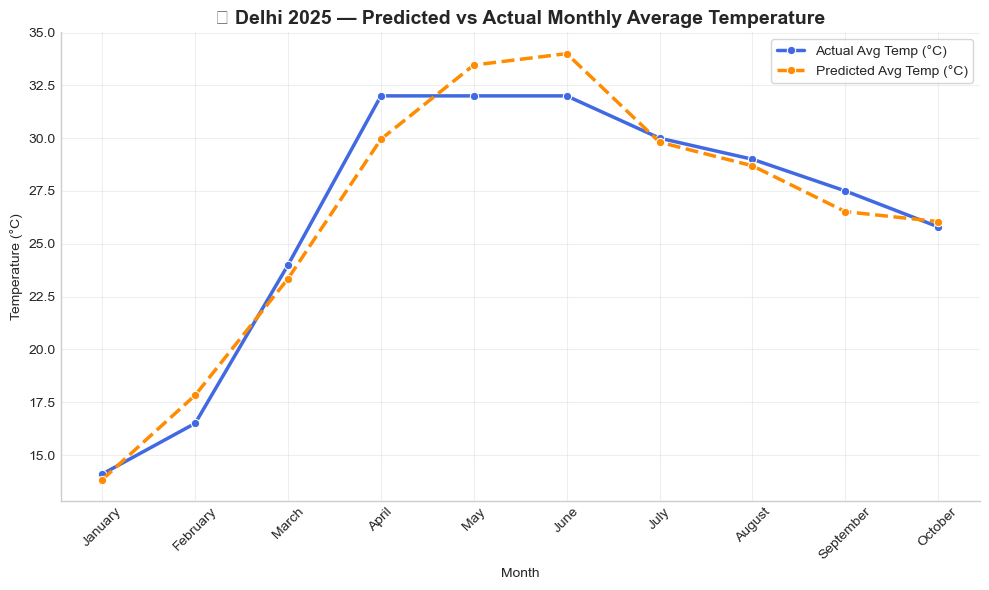

,Month,Actual_Max_Temp,Actual_Min_Temp,Actual_Avg_Temp,AvgMaxTemp,AvgMinTemp,AvgTemp
0,January,20.5,7.6,14.1,19.51,7.98,13.84
1,February,23.0,10.0,16.5,24.19,11.36,17.83
2,March,29.0,15.0,24.0,30.44,16.13,23.35
3,April,36.0,21.0,32.0,37.66,22.08,29.95
4,May,39.0,25.0,32.0,40.45,26.26,33.46
5,June,38.0,27.0,32.0,39.43,28.57,34.00
6,July,33.0,26.0,30.0,33.18,26.62,29.81
7,August,32.0,25.0,29.0,31.38,25.97,28.69
8,September,32.0,23.0,27.5,29.49,23.59,26.52
9,October,31.5,20.1,25.8,32.38,19.81,26.05


In [12]:
# 📊 Delhi 2025: SARIMAX Forecast vs Actual Observations
# -----------------------------------------------------
# This cell shows forecast accuracy, errors, and a beautiful comparison graph.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score

# --- Step 1: Define Actual 2025 Data (from your image) ---
actual_delhi = pd.DataFrame({
    "Month": [
        "January","February","March","April","May","June",
        "July","August","September","October"
    ],
    "Actual_Max_Temp": [20.5, 23.0, 29.0, 36.0, 39.0, 38.0, 33.0, 32.0, 32.0, 31.5],
    "Actual_Min_Temp": [7.6, 10.0, 15.0, 21.0, 25.0, 27.0, 26.0, 25.0, 23.0, 20.1],
    "Actual_Avg_Temp": [14.1, 16.5, 24.0, 32.0, 32.0, 32.0, 30.0, 29.0, 27.5, 25.8]
})

# --- Step 2: Extract Forecast Data for Delhi from forecast_df ---
forecast_df = forecast_df.rename(columns={
    'City': 'city', 'Metric': 'metric', 'Month': 'month', 
    'Predicted_Temperature_(°C)': 'predicted_temp'
}, errors='ignore')

delhi_forecast = forecast_df[forecast_df['city'].str.contains("Delhi", case=False)].copy()
delhi_forecast['month'] = delhi_forecast['month'].str.extract(r'(\w+)-2025')[0]

month_map = {
    'Jan': 'January','Feb': 'February','Mar': 'March','Apr': 'April','May': 'May',
    'Jun': 'June','Jul': 'July','Aug': 'August','Sep': 'September','Oct': 'October',
    'Nov': 'November','Dec': 'December'
}
delhi_forecast['Month'] = delhi_forecast['month'].map(month_map)

# Pivot to wide format
delhi_pred = delhi_forecast.pivot_table(index='Month', columns='metric', values='predicted_temp').reset_index()

# Merge actual + predicted
compare_df = pd.merge(actual_delhi, delhi_pred, on='Month', how='inner')

# --- Step 3: Compute Error Metrics and Accuracy ---
def calculate_accuracy(actual, predicted):
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    accuracy = 100 - mape
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return round(mape,2), round(accuracy,2), round(rmse,2), round(r2,3)

# Calculate for each metric
mape_max, acc_max, rmse_max, r2_max = calculate_accuracy(compare_df['Actual_Max_Temp'], compare_df['AvgMaxTemp'])
mape_min, acc_min, rmse_min, r2_min = calculate_accuracy(compare_df['Actual_Min_Temp'], compare_df['AvgMinTemp'])
mape_avg, acc_avg, rmse_avg, r2_avg = calculate_accuracy(compare_df['Actual_Avg_Temp'], compare_df['AvgTemp'])

# --- Step 4: Print Results ---
print("🌆 Delhi 2025 — Model Performance\n")
print(f"🔹 Max Temp  : Accuracy = {acc_max}% | MAPE = {mape_max}% | RMSE = {rmse_max} | R² = {r2_max}")
print(f"🔹 Min Temp  : Accuracy = {acc_min}% | MAPE = {mape_min}% | RMSE = {rmse_min} | R² = {r2_min}")
print(f"🔹 Avg Temp  : Accuracy = {acc_avg}% | MAPE = {mape_avg}% | RMSE = {rmse_avg} | R² = {r2_avg}")

# --- Step 5: Plot Predicted vs Actual (Avg Temp) ---
plt.figure(figsize=(10,6))
sns.lineplot(data=compare_df, x='Month', y='Actual_Avg_Temp', marker='o', linewidth=2.5, label='Actual Avg Temp (°C)', color='royalblue')
sns.lineplot(data=compare_df, x='Month', y='AvgTemp', marker='o', linewidth=2.5, linestyle='--', label='Predicted Avg Temp (°C)', color='darkorange')

plt.title("🌆 Delhi 2025 — Predicted vs Actual Monthly Average Temperature", fontsize=14, fontweight='bold')
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

# --- Step 6: Show Comparison Table ---
display(compare_df.round(2))


🌆 Mumbai 2025 — Model Performance
🔹 Max Temp : Accuracy=97.08% | MAPE=2.92% | RMSE=1.08 | R²=0.430
🔹 Min Temp : Accuracy=97.23% | MAPE=2.77% | RMSE=0.70 | R²=0.938
🔹 Avg Temp : Accuracy=98.77% | MAPE=1.23% | RMSE=0.38 | R²=0.948


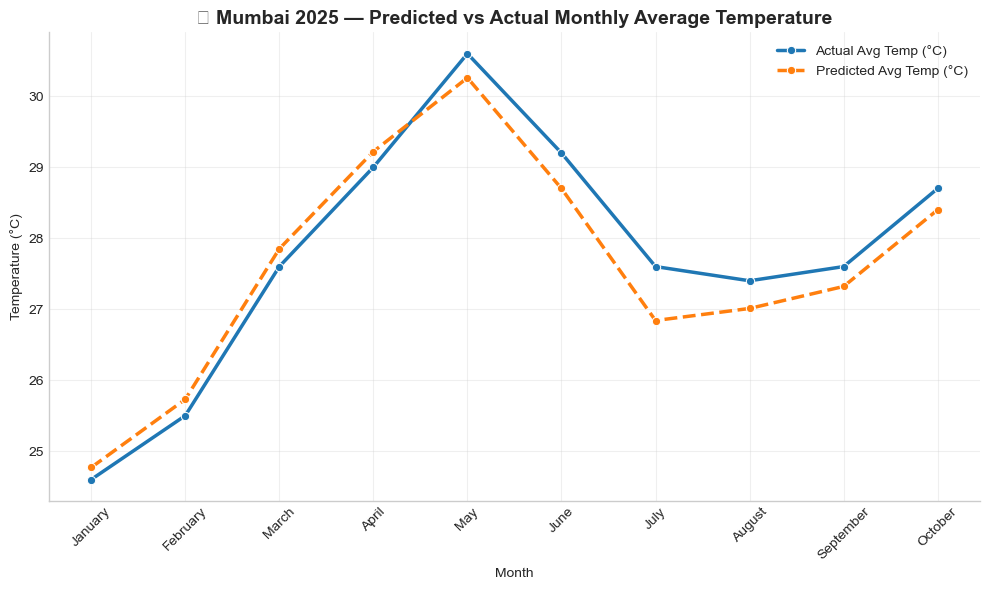

,Month,Actual_Max_Temp,Actual_Min_Temp,Actual_Avg_Temp,AvgMaxTemp,AvgMinTemp,AvgTemp
0,January,31.2,18.0,24.6,30.23,19.31,24.77
1,February,31.8,19.1,25.5,31.61,20.04,25.73
2,March,33.1,22.0,27.6,33.33,22.43,27.85
3,April,33.5,24.5,29.0,33.88,24.71,29.22
4,May,34.0,27.1,30.6,33.65,27.06,30.26
5,June,32.1,26.2,29.2,30.76,26.71,28.70
6,July,30.1,25.1,27.6,28.20,25.63,26.84
7,August,29.9,24.9,27.4,28.77,25.40,27.01
8,September,30.7,24.5,27.6,29.50,25.19,27.32
9,October,33.6,23.8,28.7,32.11,24.67,28.40


In [13]:
# 📊 Mumbai 2025 — Forecast Accuracy and Comparison
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score

actual_mumbai = pd.DataFrame({
    "Month": ["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp": [31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
    "Actual_Min_Temp": [18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8],
    "Actual_Avg_Temp": [24.6,25.5,27.6,29.0,30.6,29.2,27.6,27.4,27.6,28.7]
})

# --- Forecast Data ---
forecast_df = forecast_df.rename(columns={'City':'city','Metric':'metric','Month':'month','Predicted_Temperature_(°C)':'predicted_temp'},errors='ignore')
mumbai_forecast = forecast_df[forecast_df['city'].str.contains("Mumbai",case=False)].copy()
mumbai_forecast['month'] = mumbai_forecast['month'].str.extract(r'(\w+)-2025')[0]
month_map = {'Jan':'January','Feb':'February','Mar':'March','Apr':'April','May':'May','Jun':'June','Jul':'July','Aug':'August','Sep':'September','Oct':'October','Nov':'November','Dec':'December'}
mumbai_forecast['Month'] = mumbai_forecast['month'].map(month_map)
mumbai_pred = mumbai_forecast.pivot_table(index='Month',columns='metric',values='predicted_temp').reset_index()
compare_mumbai = pd.merge(actual_mumbai,mumbai_pred,on='Month',how='inner')

# --- Accuracy Metrics ---
def acc(actual,pred): 
    mape=mean_absolute_percentage_error(actual,pred)*100
    return 100-mape,mape,np.sqrt(mean_squared_error(actual,pred)),r2_score(actual,pred)
acc_max, mape_max, rmse_max, r2_max = acc(compare_mumbai['Actual_Max_Temp'],compare_mumbai['AvgMaxTemp'])
acc_min, mape_min, rmse_min, r2_min = acc(compare_mumbai['Actual_Min_Temp'],compare_mumbai['AvgMinTemp'])
acc_avg, mape_avg, rmse_avg, r2_avg = acc(compare_mumbai['Actual_Avg_Temp'],compare_mumbai['AvgTemp'])

print(f"🌆 Mumbai 2025 — Model Performance")
print(f"🔹 Max Temp : Accuracy={acc_max:.2f}% | MAPE={mape_max:.2f}% | RMSE={rmse_max:.2f} | R²={r2_max:.3f}")
print(f"🔹 Min Temp : Accuracy={acc_min:.2f}% | MAPE={mape_min:.2f}% | RMSE={rmse_min:.2f} | R²={r2_min:.3f}")
print(f"🔹 Avg Temp : Accuracy={acc_avg:.2f}% | MAPE={mape_avg:.2f}% | RMSE={rmse_avg:.2f} | R²={r2_avg:.3f}")

# --- Plot ---
plt.figure(figsize=(10,6))
sns.lineplot(x='Month',y='Actual_Avg_Temp',data=compare_mumbai,marker='o',label='Actual Avg Temp (°C)',linewidth=2.5)
sns.lineplot(x='Month',y='AvgTemp',data=compare_mumbai,marker='o',label='Predicted Avg Temp (°C)',linestyle='--',linewidth=2.5)
plt.title("🌆 Mumbai 2025 — Predicted vs Actual Monthly Average Temperature",fontsize=14,fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)"); plt.legend(); plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()
display(compare_mumbai.round(2))


🏙️ Bangalore 2025 — Model Performance
🔹 Max Temp : Accuracy=98.78% | MAPE=1.22% | RMSE=0.43 | R²=0.963
🔹 Min Temp : Accuracy=97.36% | MAPE=2.64% | RMSE=0.55 | R²=0.878
🔹 Avg Temp : Accuracy=98.82% | MAPE=1.18% | RMSE=0.34 | R²=0.957


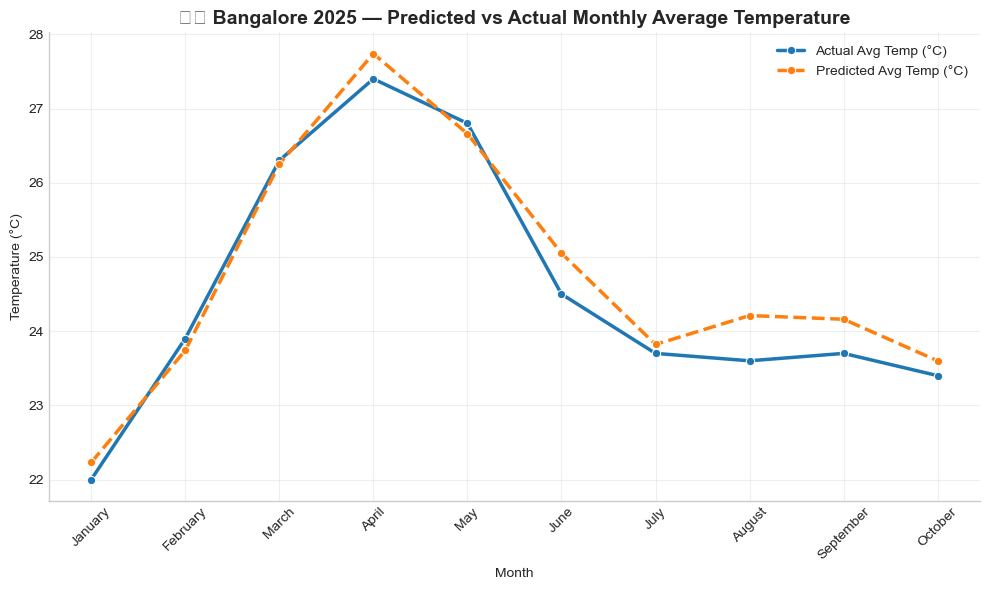

,Month,Actual_Max_Temp,Actual_Min_Temp,Actual_Avg_Temp,AvgMaxTemp,AvgMinTemp,AvgTemp
0,January,28.2,15.8,22.0,27.96,16.55,22.23
1,February,30.4,17.3,23.9,30.47,17.08,23.74
2,March,32.8,19.7,26.3,33.05,19.51,26.25
3,April,33.5,21.3,27.4,34.07,21.52,27.74
4,May,32.4,21.2,26.8,31.57,21.72,26.66
5,June,28.8,20.1,24.5,29.18,20.85,25.05
6,July,27.7,19.6,23.7,27.22,20.36,23.82
7,August,27.6,19.6,23.6,28.09,20.23,24.21
8,September,28.1,19.2,23.7,28.39,19.84,24.16
9,October,27.7,19.1,23.4,27.64,19.44,23.60


In [14]:
actual_blr = pd.DataFrame({
    "Month":["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
    "Actual_Min_Temp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1],
    "Actual_Avg_Temp":[22.0,23.9,26.3,27.4,26.8,24.5,23.7,23.6,23.7,23.4]
})
blr_forecast = forecast_df[forecast_df['city'].str.contains("Bangalore",case=False)].copy()
blr_forecast['month']=blr_forecast['month'].str.extract(r'(\w+)-2025')[0];blr_forecast['Month']=blr_forecast['month'].map(month_map)
blr_pred=blr_forecast.pivot_table(index='Month',columns='metric',values='predicted_temp').reset_index()
compare_blr=pd.merge(actual_blr,blr_pred,on='Month',how='inner')
acc_max,mape_max,rmse_max,r2_max=acc(compare_blr['Actual_Max_Temp'],compare_blr['AvgMaxTemp'])
acc_min,mape_min,rmse_min,r2_min=acc(compare_blr['Actual_Min_Temp'],compare_blr['AvgMinTemp'])
acc_avg,mape_avg,rmse_avg,r2_avg=acc(compare_blr['Actual_Avg_Temp'],compare_blr['AvgTemp'])
print(f"🏙️ Bangalore 2025 — Model Performance")
print(f"🔹 Max Temp : Accuracy={acc_max:.2f}% | MAPE={mape_max:.2f}% | RMSE={rmse_max:.2f} | R²={r2_max:.3f}")
print(f"🔹 Min Temp : Accuracy={acc_min:.2f}% | MAPE={mape_min:.2f}% | RMSE={rmse_min:.2f} | R²={r2_min:.3f}")
print(f"🔹 Avg Temp : Accuracy={acc_avg:.2f}% | MAPE={mape_avg:.2f}% | RMSE={rmse_avg:.2f} | R²={r2_avg:.3f}")
plt.figure(figsize=(10,6))
sns.lineplot(x='Month',y='Actual_Avg_Temp',data=compare_blr,marker='o',label='Actual Avg Temp (°C)',linewidth=2.5)
sns.lineplot(x='Month',y='AvgTemp',data=compare_blr,marker='o',label='Predicted Avg Temp (°C)',linestyle='--',linewidth=2.5)
plt.title("🏙️ Bangalore 2025 — Predicted vs Actual Monthly Average Temperature",fontsize=14,fontweight='bold')
plt.xlabel("Month");plt.ylabel("Temperature (°C)");plt.legend();plt.grid(alpha=0.3);plt.xticks(rotation=45);sns.despine();plt.tight_layout();plt.show()
display(compare_blr.round(2))


🏙️ Hyderabad 2025 — Model Performance
🔹 Max Temp : Accuracy=96.66% | MAPE=3.34% | RMSE=1.27 | R²=0.866
🔹 Min Temp : Accuracy=97.51% | MAPE=2.49% | RMSE=0.71 | R²=0.939
🔹 Avg Temp : Accuracy=97.72% | MAPE=2.28% | RMSE=0.79 | R²=0.925


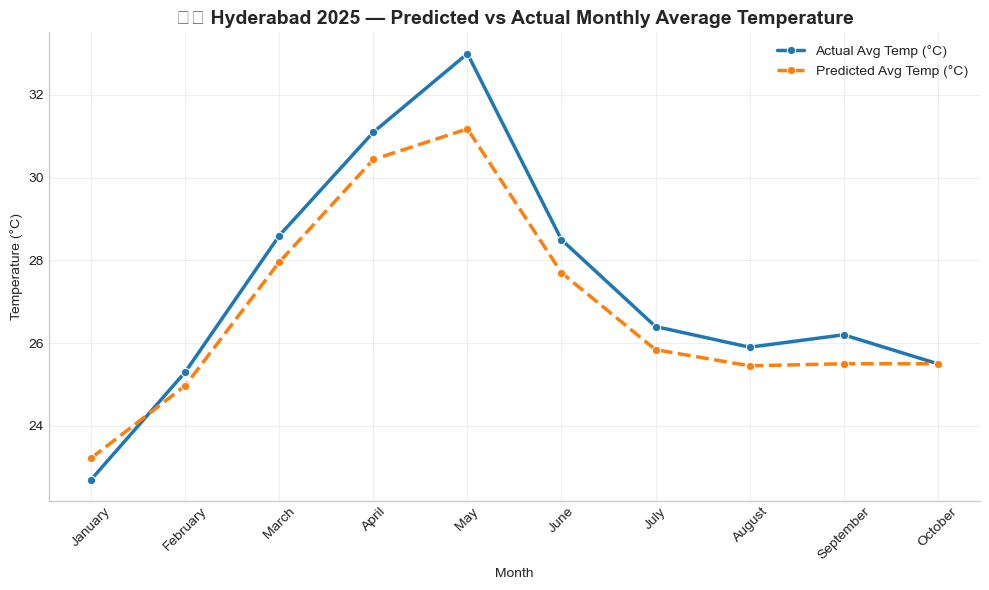

,Month,Actual_Max_Temp,Actual_Min_Temp,Actual_Avg_Temp,AvgMaxTemp,AvgMinTemp,AvgTemp
0,January,29.1,16.2,22.7,28.65,17.79,23.22
1,February,31.8,18.8,25.3,31.40,18.46,24.97
2,March,35.3,21.9,28.6,34.52,21.33,27.96
3,April,37.4,24.8,31.1,36.68,24.13,30.44
4,May,39.2,26.8,33.0,36.78,25.60,31.18
5,June,32.8,24.2,28.5,31.02,24.32,27.70
6,July,29.7,23.1,26.4,28.28,23.31,25.84
7,August,29.2,22.7,25.9,28.11,22.72,25.45
8,September,29.8,22.6,26.2,28.27,22.64,25.50
9,October,30.1,20.8,25.5,29.73,21.17,25.50


In [15]:
actual_hyd = pd.DataFrame({
    "Month":["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
    "Actual_Min_Temp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8],
    "Actual_Avg_Temp":[22.7,25.3,28.6,31.1,33.0,28.5,26.4,25.9,26.2,25.5]
})
hyd_forecast = forecast_df[forecast_df['city'].str.contains("Hyderabad",case=False)].copy()
hyd_forecast['month']=hyd_forecast['month'].str.extract(r'(\w+)-2025')[0];hyd_forecast['Month']=hyd_forecast['month'].map(month_map)
hyd_pred=hyd_forecast.pivot_table(index='Month',columns='metric',values='predicted_temp').reset_index()
compare_hyd=pd.merge(actual_hyd,hyd_pred,on='Month',how='inner')
acc_max,mape_max,rmse_max,r2_max=acc(compare_hyd['Actual_Max_Temp'],compare_hyd['AvgMaxTemp'])
acc_min,mape_min,rmse_min,r2_min=acc(compare_hyd['Actual_Min_Temp'],compare_hyd['AvgMinTemp'])
acc_avg,mape_avg,rmse_avg,r2_avg=acc(compare_hyd['Actual_Avg_Temp'],compare_hyd['AvgTemp'])
print(f"🏙️ Hyderabad 2025 — Model Performance")
print(f"🔹 Max Temp : Accuracy={acc_max:.2f}% | MAPE={mape_max:.2f}% | RMSE={rmse_max:.2f} | R²={r2_max:.3f}")
print(f"🔹 Min Temp : Accuracy={acc_min:.2f}% | MAPE={mape_min:.2f}% | RMSE={rmse_min:.2f} | R²={r2_min:.3f}")
print(f"🔹 Avg Temp : Accuracy={acc_avg:.2f}% | MAPE={mape_avg:.2f}% | RMSE={rmse_avg:.2f} | R²={r2_avg:.3f}")
plt.figure(figsize=(10,6))
sns.lineplot(x='Month',y='Actual_Avg_Temp',data=compare_hyd,marker='o',label='Actual Avg Temp (°C)',linewidth=2.5)
sns.lineplot(x='Month',y='AvgTemp',data=compare_hyd,marker='o',label='Predicted Avg Temp (°C)',linestyle='--',linewidth=2.5)
plt.title("🏙️ Hyderabad 2025 — Predicted vs Actual Monthly Average Temperature",fontsize=14,fontweight='bold')
plt.xlabel("Month");plt.ylabel("Temperature (°C)");plt.legend();plt.grid(alpha=0.3);plt.xticks(rotation=45);sns.despine();plt.tight_layout();plt.show()
display(compare_hyd.round(2))


🏙️ Chennai 2025 — Model Performance
🔹 Max Temp : Accuracy=96.96% | MAPE=3.04% | RMSE=1.26 | R²=0.744
🔹 Min Temp : Accuracy=98.37% | MAPE=1.63% | RMSE=0.52 | R²=0.932
🔹 Avg Temp : Accuracy=97.98% | MAPE=2.02% | RMSE=0.80 | R²=0.869


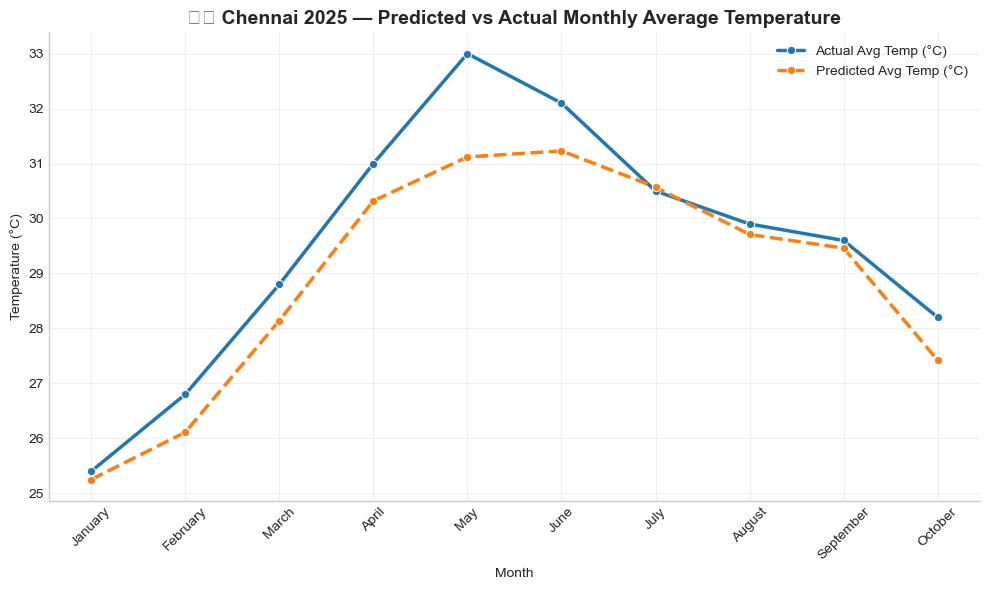

,Month,Actual_Max_Temp,Actual_Min_Temp,Actual_Avg_Temp,AvgMaxTemp,AvgMinTemp,AvgTemp
0,January,29.2,21.5,25.4,28.31,22.35,25.25
1,February,31.1,22.4,26.8,30.16,22.33,26.11
2,March,33.3,24.2,28.8,32.38,24.29,28.14
3,April,35.2,26.8,31.0,34.36,26.74,30.32
4,May,37.8,28.2,33.0,34.96,27.72,31.12
5,June,36.9,27.3,32.1,35.23,27.67,31.23
6,July,34.8,26.2,30.5,34.52,27.05,30.57
7,August,34.1,25.7,29.9,33.58,26.23,29.71
8,September,33.8,25.3,29.6,33.27,26.08,29.46
9,October,31.7,24.6,28.2,30.66,24.61,27.42


In [16]:
actual_che = pd.DataFrame({
    "Month":["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
    "Actual_Min_Temp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6],
    "Actual_Avg_Temp":[25.4,26.8,28.8,31.0,33.0,32.1,30.5,29.9,29.6,28.2]
})
che_forecast = forecast_df[forecast_df['city'].str.contains("Chennai",case=False)].copy()
che_forecast['month']=che_forecast['month'].str.extract(r'(\w+)-2025')[0];che_forecast['Month']=che_forecast['month'].map(month_map)
che_pred=che_forecast.pivot_table(index='Month',columns='metric',values='predicted_temp').reset_index()
compare_che=pd.merge(actual_che,che_pred,on='Month',how='inner')
acc_max,mape_max,rmse_max,r2_max=acc(compare_che['Actual_Max_Temp'],compare_che['AvgMaxTemp'])
acc_min,mape_min,rmse_min,r2_min=acc(compare_che['Actual_Min_Temp'],compare_che['AvgMinTemp'])
acc_avg,mape_avg,rmse_avg,r2_avg=acc(compare_che['Actual_Avg_Temp'],compare_che['AvgTemp'])
print(f"🏙️ Chennai 2025 — Model Performance")
print(f"🔹 Max Temp : Accuracy={acc_max:.2f}% | MAPE={mape_max:.2f}% | RMSE={rmse_max:.2f} | R²={r2_max:.3f}")
print(f"🔹 Min Temp : Accuracy={acc_min:.2f}% | MAPE={mape_min:.2f}% | RMSE={rmse_min:.2f} | R²={r2_min:.3f}")
print(f"🔹 Avg Temp : Accuracy={acc_avg:.2f}% | MAPE={mape_avg:.2f}% | RMSE={rmse_avg:.2f} | R²={r2_avg:.3f}")
plt.figure(figsize=(10,6))
sns.lineplot(x='Month',y='Actual_Avg_Temp',data=compare_che,marker='o',label='Actual Avg Temp (°C)',linewidth=2.5)
sns.lineplot(x='Month',y='AvgTemp',data=compare_che,marker='o',label='Predicted Avg Temp (°C)',linestyle='--',linewidth=2.5)
plt.title("🏙️ Chennai 2025 — Predicted vs Actual Monthly Average Temperature",fontsize=14,fontweight='bold')
plt.xlabel("Month");plt.ylabel("Temperature (°C)");plt.legend();plt.grid(alpha=0.3);plt.xticks(rotation=45);sns.despine();plt.tight_layout();plt.show()
display(compare_che.round(2))


In [17]:
import pandas as pd
import numpy as np

# -------- Step 1: Define actual data again for Delhi & Mumbai --------
actual_delhi = pd.DataFrame({
    "Month":["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
    "Actual_Min_Temp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1],
    "Actual_Avg_Temp":[14.1,16.5,24.0,32.0,32.0,32.0,30.0,29.0,27.5,25.8]
})

actual_mumbai = pd.DataFrame({
    "Month":["January","February","March","April","May","June","July","August","September","October"],
    "Actual_Max_Temp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
    "Actual_Min_Temp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8],
    "Actual_Avg_Temp":[24.6,25.5,27.6,29.0,30.6,29.2,27.6,27.4,27.6,28.7]
})

# -------- Step 2: Prepare forecasted data from forecast_df --------
forecast_df = forecast_df.rename(columns={
    'City': 'city', 'Metric': 'metric', 'Month': 'month',
    'Predicted_Temperature_(°C)': 'predicted_temp'
}, errors='ignore')

def get_forecast_city(city):
    df = forecast_df[forecast_df['city'].str.contains(city, case=False)].copy()
    df['month'] = df['month'].str.extract(r'(\w+)-2025')[0]
    month_map = {
        'Jan':'January','Feb':'February','Mar':'March','Apr':'April','May':'May',
        'Jun':'June','Jul':'July','Aug':'August','Sep':'September','Oct':'October','Nov':'November','Dec':'December'
    }
    df['Month'] = df['month'].map(month_map)
    pivot = df.pivot_table(index='Month', columns='metric', values='predicted_temp').reset_index()
    return pivot

delhi_pred = get_forecast_city("Delhi")
mumbai_pred = get_forecast_city("Mumbai")

# -------- Step 3: Merge actual + predicted and compute differences --------
def merge_and_diff(actual_df, pred_df, city_name):
    merged = pd.merge(actual_df, pred_df, on='Month', how='inner')
    merged['Δ Max'] = (merged['AvgMaxTemp'] - merged['Actual_Max_Temp']).round(2)
    merged['Δ Min'] = (merged['AvgMinTemp'] - merged['Actual_Min_Temp']).round(2)
    merged['Δ Avg'] = (merged['AvgTemp'] - merged['Actual_Avg_Temp']).round(2)
    print(f"\n🌆 {city_name} — Actual vs Predicted (2025)\n")
    display(merged[['Month',
                    'Actual_Max_Temp','AvgMaxTemp','Δ Max',
                    'Actual_Min_Temp','AvgMinTemp','Δ Min',
                    'Actual_Avg_Temp','AvgTemp','Δ Avg']].round(2))

merge_and_diff(actual_delhi, delhi_pred, "Delhi")
merge_and_diff(actual_mumbai, mumbai_pred, "Mumbai")



🌆 Delhi — Actual vs Predicted (2025)



,Month,Actual_Max_Temp,AvgMaxTemp,Δ Max,Actual_Min_Temp,AvgMinTemp,Δ Min,Actual_Avg_Temp,AvgTemp,Δ Avg
0,January,20.5,19.51,-0.99,7.6,7.98,0.38,14.1,13.84,-0.26
1,February,23.0,24.19,1.19,10.0,11.36,1.36,16.5,17.83,1.33
2,March,29.0,30.44,1.44,15.0,16.13,1.13,24.0,23.35,-0.65
3,April,36.0,37.66,1.66,21.0,22.08,1.08,32.0,29.95,-2.05
4,May,39.0,40.45,1.45,25.0,26.26,1.26,32.0,33.46,1.46
5,June,38.0,39.43,1.43,27.0,28.57,1.57,32.0,34.00,2.00
6,July,33.0,33.18,0.18,26.0,26.62,0.62,30.0,29.81,-0.19
7,August,32.0,31.38,-0.62,25.0,25.97,0.97,29.0,28.69,-0.31
8,September,32.0,29.49,-2.51,23.0,23.59,0.59,27.5,26.52,-0.98
9,October,31.5,32.38,0.88,20.1,19.81,-0.29,25.8,26.05,0.25



🌆 Mumbai — Actual vs Predicted (2025)



,Month,Actual_Max_Temp,AvgMaxTemp,Δ Max,Actual_Min_Temp,AvgMinTemp,Δ Min,Actual_Avg_Temp,AvgTemp,Δ Avg
0,January,31.2,30.23,-0.97,18.0,19.31,1.31,24.6,24.77,0.17
1,February,31.8,31.61,-0.19,19.1,20.04,0.94,25.5,25.73,0.23
2,March,33.1,33.33,0.23,22.0,22.43,0.43,27.6,27.85,0.25
3,April,33.5,33.88,0.38,24.5,24.71,0.21,29.0,29.22,0.22
4,May,34.0,33.65,-0.35,27.1,27.06,-0.04,30.6,30.26,-0.34
5,June,32.1,30.76,-1.34,26.2,26.71,0.51,29.2,28.70,-0.50
6,July,30.1,28.20,-1.90,25.1,25.63,0.53,27.6,26.84,-0.76
7,August,29.9,28.77,-1.13,24.9,25.40,0.50,27.4,27.01,-0.39
8,September,30.7,29.50,-1.20,24.5,25.19,0.69,27.6,27.32,-0.28
9,October,33.6,32.11,-1.49,23.8,24.67,0.87,28.7,28.40,-0.30


c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


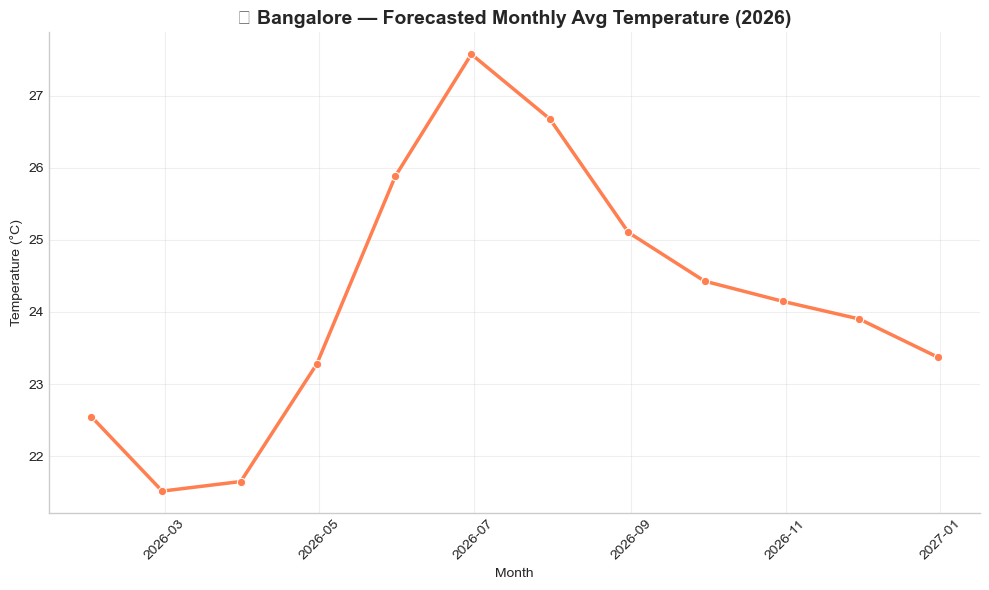

,Month,Forecasted_Avg_Temp_°C
310,January,22.55
311,February,21.52
312,March,21.65
313,April,23.28
314,May,25.88
315,June,27.57
316,July,26.68
317,August,25.10
318,September,24.43
319,October,24.15


In [18]:
# ✅ Universal SARIMAX 2026 Forecast (No NaN/Inf issues)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prepare_monthly(df_city):
    df_city = df_city.copy()
    df_city['date'] = pd.to_datetime(df_city['date'])
    df_city = df_city.sort_values('date').set_index('date')
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2
    monthly = df_city.resample('M').mean(numeric_only=True)
    monthly = monthly[['temperature_2m_max','temperature_2m_min','avg_temp',
                       'precipitation_sum','wind_speed_10m_max']].copy()
    monthly = monthly.fillna(method='ffill').fillna(method='bfill')  # ✅ Fill NaN
    return monthly

def fit_and_forecast_sarimax(series, exog, steps):
    # Clean NaN & Inf values
    exog = exog.replace([np.inf, -np.inf], np.nan).fillna(exog.mean())
    series = series.replace([np.inf, -np.inf], np.nan).fillna(series.mean())
    series, exog = series.align(exog, join='inner', axis=0)
    
    model = SARIMAX(series, exog=exog, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False)
    
    future_exog = np.tile(exog.mean().values, (steps, 1))  # use mean exog for next 12 months
    forecast = fitted.forecast(steps=steps, exog=future_exog)
    return forecast

# -------------------------
# Change this to run for each city
# -------------------------
city = "Bangalore"   # 👈 change to Delhi, Mumbai, Hyderabad, Chennai
# -------------------------

city_df = df[df['city'].str.contains(city, case=False)]
monthly = prepare_monthly(city_df)

# Add actual 2025 avg temps for each city manually:
if city == "Delhi":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
        "AvgMinTemp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
    })
elif city == "Mumbai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
        "AvgMinTemp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8]
    })
elif city == "Bangalore":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
        "AvgMinTemp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1]
    })
elif city == "Hyderabad":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
        "AvgMinTemp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8]
    })
elif city == "Chennai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
        "AvgMinTemp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6]
    })

# Compute average
actual_2025['avg_temp'] = (actual_2025['AvgMaxTemp'] + actual_2025['AvgMinTemp']) / 2

# Append 2025 values
for i, temp in enumerate(actual_2025['avg_temp']):
    date = pd.Timestamp(f"2025-{i+1:02d}-28")
    monthly.loc[date] = [np.nan, np.nan, temp, monthly['precipitation_sum'].mean(), monthly['wind_speed_10m_max'].mean()]

# --- Forecast 2026 ---
forecast_2026 = fit_and_forecast_sarimax(monthly['avg_temp'], monthly[['precipitation_sum','wind_speed_10m_max']], 12)

# --- Plot ---
months_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
plt.figure(figsize=(10,6))
sns.lineplot(x=months_2026, y=forecast_2026, marker='o', linewidth=2.5, color='coral')
plt.title(f"🌆 {city} — Forecasted Monthly Avg Temperature (2026)", fontsize=14, fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()

# --- Display forecast table ---
display(pd.DataFrame({
    "Month": [d.strftime('%B') for d in months_2026],
    "Forecasted_Avg_Temp_°C": forecast_2026.round(2)
}))


c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


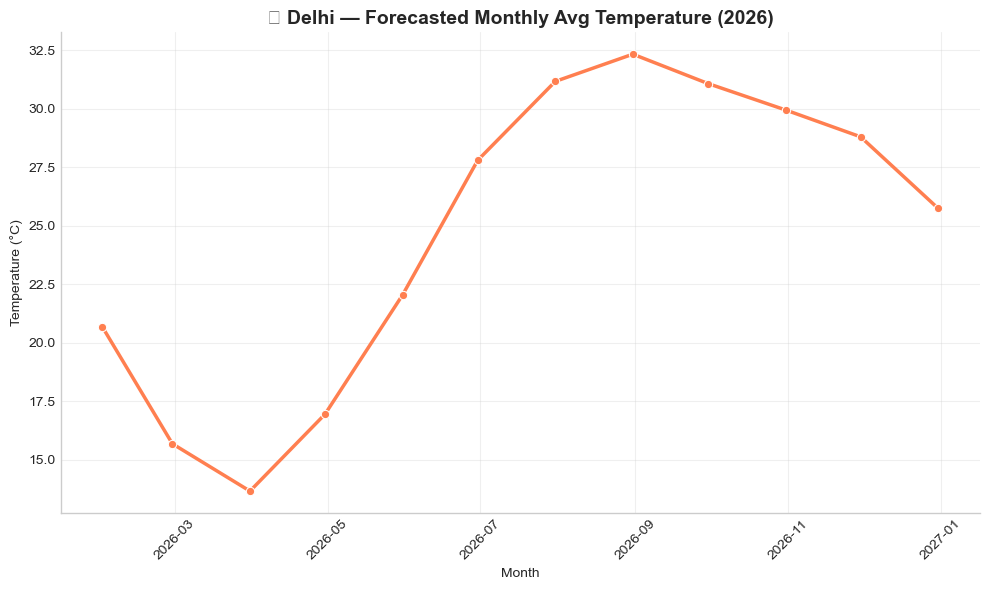

,Month,Forecasted_Avg_Temp_°C
310,January,20.68
311,February,15.68
312,March,13.66
313,April,16.94
314,May,22.04
315,June,27.80
316,July,31.17
317,August,32.33
318,September,31.08
319,October,29.95


In [19]:
# ✅ Universal SARIMAX 2026 Forecast (No NaN/Inf issues)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prepare_monthly(df_city):
    df_city = df_city.copy()
    df_city['date'] = pd.to_datetime(df_city['date'])
    df_city = df_city.sort_values('date').set_index('date')
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2
    monthly = df_city.resample('M').mean(numeric_only=True)
    monthly = monthly[['temperature_2m_max','temperature_2m_min','avg_temp',
                       'precipitation_sum','wind_speed_10m_max']].copy()
    monthly = monthly.fillna(method='ffill').fillna(method='bfill')  # ✅ Fill NaN
    return monthly

def fit_and_forecast_sarimax(series, exog, steps):
    # Clean NaN & Inf values
    exog = exog.replace([np.inf, -np.inf], np.nan).fillna(exog.mean())
    series = series.replace([np.inf, -np.inf], np.nan).fillna(series.mean())
    series, exog = series.align(exog, join='inner', axis=0)
    
    model = SARIMAX(series, exog=exog, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False)
    
    future_exog = np.tile(exog.mean().values, (steps, 1))  # use mean exog for next 12 months
    forecast = fitted.forecast(steps=steps, exog=future_exog)
    return forecast

# -------------------------
# Change this to run for each city
# -------------------------
city = "Delhi"   # 👈 change to Delhi, Mumbai, Hyderabad, Chennai
# -------------------------

city_df = df[df['city'].str.contains(city, case=False)]
monthly = prepare_monthly(city_df)

# Add actual 2025 avg temps for each city manually:
if city == "Delhi":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
        "AvgMinTemp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
    })
elif city == "Mumbai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
        "AvgMinTemp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8]
    })
elif city == "Bangalore":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
        "AvgMinTemp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1]
    })
elif city == "Hyderabad":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
        "AvgMinTemp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8]
    })
elif city == "Chennai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
        "AvgMinTemp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6]
    })

# Compute average
actual_2025['avg_temp'] = (actual_2025['AvgMaxTemp'] + actual_2025['AvgMinTemp']) / 2

# Append 2025 values
for i, temp in enumerate(actual_2025['avg_temp']):
    date = pd.Timestamp(f"2025-{i+1:02d}-28")
    monthly.loc[date] = [np.nan, np.nan, temp, monthly['precipitation_sum'].mean(), monthly['wind_speed_10m_max'].mean()]

# --- Forecast 2026 ---
forecast_2026 = fit_and_forecast_sarimax(monthly['avg_temp'], monthly[['precipitation_sum','wind_speed_10m_max']], 12)

# --- Plot ---
months_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
plt.figure(figsize=(10,6))
sns.lineplot(x=months_2026, y=forecast_2026, marker='o', linewidth=2.5, color='coral')
plt.title(f"🌆 {city} — Forecasted Monthly Avg Temperature (2026)", fontsize=14, fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()

# --- Display forecast table ---
display(pd.DataFrame({
    "Month": [d.strftime('%B') for d in months_2026],
    "Forecasted_Avg_Temp_°C": forecast_2026.round(2)
}))


c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


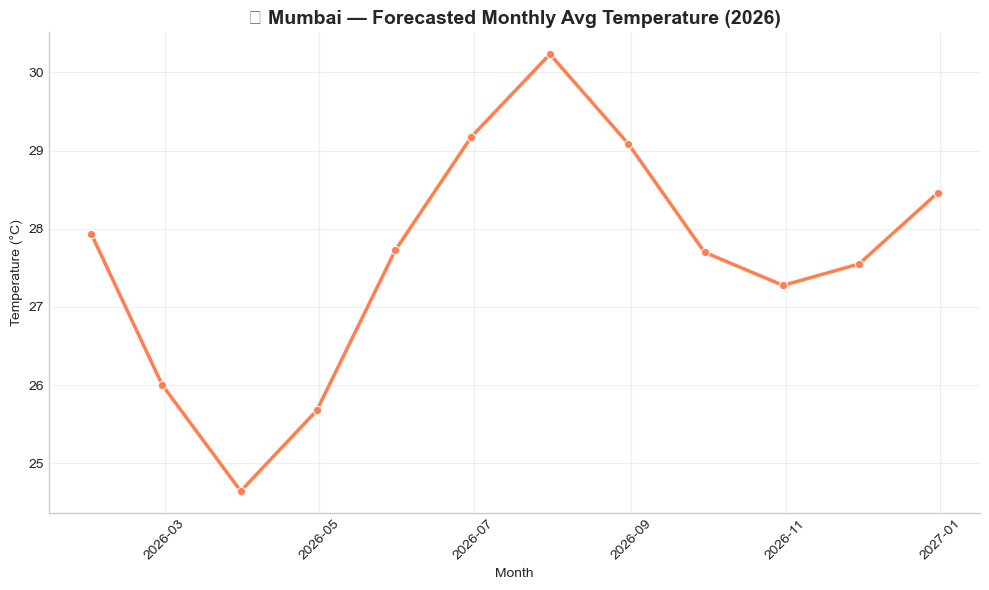

,Month,Forecasted_Avg_Temp_°C
310,January,27.94
311,February,26.00
312,March,24.64
313,April,25.68
314,May,27.72
315,June,29.18
316,July,30.23
317,August,29.08
318,September,27.70
319,October,27.27


In [20]:
# ✅ Universal SARIMAX 2026 Forecast (No NaN/Inf issues)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prepare_monthly(df_city):
    df_city = df_city.copy()
    df_city['date'] = pd.to_datetime(df_city['date'])
    df_city = df_city.sort_values('date').set_index('date')
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2
    monthly = df_city.resample('M').mean(numeric_only=True)
    monthly = monthly[['temperature_2m_max','temperature_2m_min','avg_temp',
                       'precipitation_sum','wind_speed_10m_max']].copy()
    monthly = monthly.fillna(method='ffill').fillna(method='bfill')  # ✅ Fill NaN
    return monthly

def fit_and_forecast_sarimax(series, exog, steps):
    # Clean NaN & Inf values
    exog = exog.replace([np.inf, -np.inf], np.nan).fillna(exog.mean())
    series = series.replace([np.inf, -np.inf], np.nan).fillna(series.mean())
    series, exog = series.align(exog, join='inner', axis=0)
    
    model = SARIMAX(series, exog=exog, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False)
    
    future_exog = np.tile(exog.mean().values, (steps, 1))  # use mean exog for next 12 months
    forecast = fitted.forecast(steps=steps, exog=future_exog)
    return forecast

# -------------------------
# Change this to run for each city
# -------------------------
city = "Mumbai"   # 👈 change to Delhi, Mumbai, Hyderabad, Chennai
# -------------------------

city_df = df[df['city'].str.contains(city, case=False)]
monthly = prepare_monthly(city_df)

# Add actual 2025 avg temps for each city manually:
if city == "Delhi":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
        "AvgMinTemp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
    })
elif city == "Mumbai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
        "AvgMinTemp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8]
    })
elif city == "Bangalore":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
        "AvgMinTemp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1]
    })
elif city == "Hyderabad":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
        "AvgMinTemp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8]
    })
elif city == "Chennai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
        "AvgMinTemp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6]
    })

# Compute average
actual_2025['avg_temp'] = (actual_2025['AvgMaxTemp'] + actual_2025['AvgMinTemp']) / 2

# Append 2025 values
for i, temp in enumerate(actual_2025['avg_temp']):
    date = pd.Timestamp(f"2025-{i+1:02d}-28")
    monthly.loc[date] = [np.nan, np.nan, temp, monthly['precipitation_sum'].mean(), monthly['wind_speed_10m_max'].mean()]

# --- Forecast 2026 ---
forecast_2026 = fit_and_forecast_sarimax(monthly['avg_temp'], monthly[['precipitation_sum','wind_speed_10m_max']], 12)

# --- Plot ---
months_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
plt.figure(figsize=(10,6))
sns.lineplot(x=months_2026, y=forecast_2026, marker='o', linewidth=2.5, color='coral')
plt.title(f"🌆 {city} — Forecasted Monthly Avg Temperature (2026)", fontsize=14, fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()

# --- Display forecast table ---
display(pd.DataFrame({
    "Month": [d.strftime('%B') for d in months_2026],
    "Forecasted_Avg_Temp_°C": forecast_2026.round(2)
}))


c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


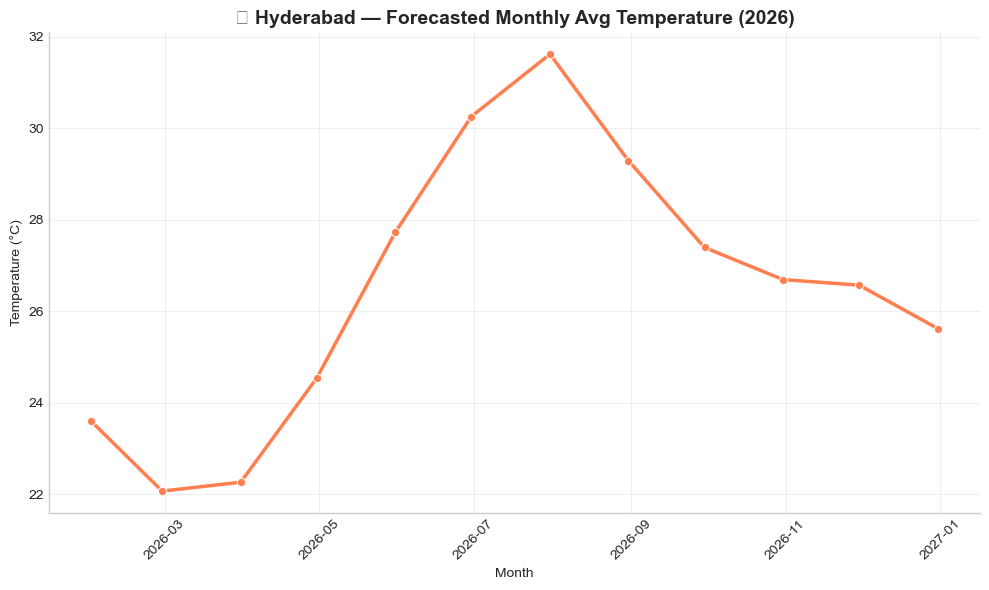

,Month,Forecasted_Avg_Temp_°C
310,January,23.59
311,February,22.07
312,March,22.26
313,April,24.54
314,May,27.73
315,June,30.25
316,July,31.62
317,August,29.29
318,September,27.39
319,October,26.69


In [21]:
# ✅ Universal SARIMAX 2026 Forecast (No NaN/Inf issues)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prepare_monthly(df_city):
    df_city = df_city.copy()
    df_city['date'] = pd.to_datetime(df_city['date'])
    df_city = df_city.sort_values('date').set_index('date')
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2
    monthly = df_city.resample('M').mean(numeric_only=True)
    monthly = monthly[['temperature_2m_max','temperature_2m_min','avg_temp',
                       'precipitation_sum','wind_speed_10m_max']].copy()
    monthly = monthly.fillna(method='ffill').fillna(method='bfill')  # ✅ Fill NaN
    return monthly

def fit_and_forecast_sarimax(series, exog, steps):
    # Clean NaN & Inf values
    exog = exog.replace([np.inf, -np.inf], np.nan).fillna(exog.mean())
    series = series.replace([np.inf, -np.inf], np.nan).fillna(series.mean())
    series, exog = series.align(exog, join='inner', axis=0)
    
    model = SARIMAX(series, exog=exog, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False)
    
    future_exog = np.tile(exog.mean().values, (steps, 1))  # use mean exog for next 12 months
    forecast = fitted.forecast(steps=steps, exog=future_exog)
    return forecast

# -------------------------
# Change this to run for each city
# -------------------------
city = "Hyderabad"   # 👈 change to Delhi, Mumbai, Hyderabad, Chennai
# -------------------------

city_df = df[df['city'].str.contains(city, case=False)]
monthly = prepare_monthly(city_df)

# Add actual 2025 avg temps for each city manually:
if city == "Delhi":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
        "AvgMinTemp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
    })
elif city == "Mumbai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
        "AvgMinTemp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8]
    })
elif city == "Bangalore":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
        "AvgMinTemp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1]
    })
elif city == "Hyderabad":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
        "AvgMinTemp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8]
    })
elif city == "Chennai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
        "AvgMinTemp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6]
    })

# Compute average
actual_2025['avg_temp'] = (actual_2025['AvgMaxTemp'] + actual_2025['AvgMinTemp']) / 2

# Append 2025 values
for i, temp in enumerate(actual_2025['avg_temp']):
    date = pd.Timestamp(f"2025-{i+1:02d}-28")
    monthly.loc[date] = [np.nan, np.nan, temp, monthly['precipitation_sum'].mean(), monthly['wind_speed_10m_max'].mean()]

# --- Forecast 2026 ---
forecast_2026 = fit_and_forecast_sarimax(monthly['avg_temp'], monthly[['precipitation_sum','wind_speed_10m_max']], 12)

# --- Plot ---
months_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
plt.figure(figsize=(10,6))
sns.lineplot(x=months_2026, y=forecast_2026, marker='o', linewidth=2.5, color='coral')
plt.title(f"🌆 {city} — Forecasted Monthly Avg Temperature (2026)", fontsize=14, fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()

# --- Display forecast table ---
display(pd.DataFrame({
    "Month": [d.strftime('%B') for d in months_2026],
    "Forecasted_Avg_Temp_°C": forecast_2026.round(2)
}))


c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aryan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


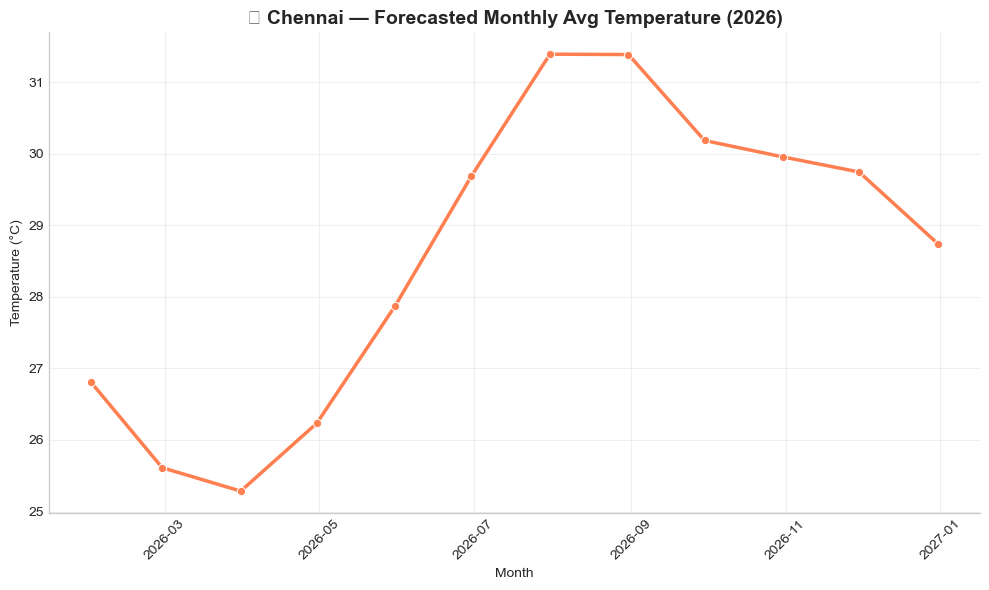

,Month,Forecasted_Avg_Temp_°C
310,January,26.80
311,February,25.61
312,March,25.29
313,April,26.23
314,May,27.88
315,June,29.68
316,July,31.39
317,August,31.38
318,September,30.18
319,October,29.95


In [22]:
# ✅ Universal SARIMAX 2026 Forecast (No NaN/Inf issues)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX

def prepare_monthly(df_city):
    df_city = df_city.copy()
    df_city['date'] = pd.to_datetime(df_city['date'])
    df_city = df_city.sort_values('date').set_index('date')
    df_city['avg_temp'] = (df_city['temperature_2m_max'] + df_city['temperature_2m_min']) / 2
    monthly = df_city.resample('M').mean(numeric_only=True)
    monthly = monthly[['temperature_2m_max','temperature_2m_min','avg_temp',
                       'precipitation_sum','wind_speed_10m_max']].copy()
    monthly = monthly.fillna(method='ffill').fillna(method='bfill')  # ✅ Fill NaN
    return monthly

def fit_and_forecast_sarimax(series, exog, steps):
    # Clean NaN & Inf values
    exog = exog.replace([np.inf, -np.inf], np.nan).fillna(exog.mean())
    series = series.replace([np.inf, -np.inf], np.nan).fillna(series.mean())
    series, exog = series.align(exog, join='inner', axis=0)
    
    model = SARIMAX(series, exog=exog, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False)
    
    future_exog = np.tile(exog.mean().values, (steps, 1))  # use mean exog for next 12 months
    forecast = fitted.forecast(steps=steps, exog=future_exog)
    return forecast

# -------------------------
# Change this to run for each city
# -------------------------
city = "Chennai"   # 👈 change to Delhi, Mumbai, Hyderabad, Chennai
# -------------------------

city_df = df[df['city'].str.contains(city, case=False)]
monthly = prepare_monthly(city_df)

# Add actual 2025 avg temps for each city manually:
if city == "Delhi":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
        "AvgMinTemp":[7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
    })
elif city == "Mumbai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[31.2,31.8,33.1,33.5,34.0,32.1,30.1,29.9,30.7,33.6],
        "AvgMinTemp":[18.0,19.1,22.0,24.5,27.1,26.2,25.1,24.9,24.5,23.8]
    })
elif city == "Bangalore":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[28.2,30.4,32.8,33.5,32.4,28.8,27.7,27.6,28.1,27.7],
        "AvgMinTemp":[15.8,17.3,19.7,21.3,21.2,20.1,19.6,19.6,19.2,19.1]
    })
elif city == "Hyderabad":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.1,31.8,35.3,37.4,39.2,32.8,29.7,29.2,29.8,30.1],
        "AvgMinTemp":[16.2,18.8,21.9,24.8,26.8,24.2,23.1,22.7,22.6,20.8]
    })
elif city == "Chennai":
    actual_2025 = pd.DataFrame({
        "AvgMaxTemp":[29.2,31.1,33.3,35.2,37.8,36.9,34.8,34.1,33.8,31.7],
        "AvgMinTemp":[21.5,22.4,24.2,26.8,28.2,27.3,26.2,25.7,25.3,24.6]
    })

# Compute average
actual_2025['avg_temp'] = (actual_2025['AvgMaxTemp'] + actual_2025['AvgMinTemp']) / 2

# Append 2025 values
for i, temp in enumerate(actual_2025['avg_temp']):
    date = pd.Timestamp(f"2025-{i+1:02d}-28")
    monthly.loc[date] = [np.nan, np.nan, temp, monthly['precipitation_sum'].mean(), monthly['wind_speed_10m_max'].mean()]

# --- Forecast 2026 ---
forecast_2026 = fit_and_forecast_sarimax(monthly['avg_temp'], monthly[['precipitation_sum','wind_speed_10m_max']], 12)

# --- Plot ---
months_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
plt.figure(figsize=(10,6))
sns.lineplot(x=months_2026, y=forecast_2026, marker='o', linewidth=2.5, color='coral')
plt.title(f"🌆 {city} — Forecasted Monthly Avg Temperature (2026)", fontsize=14, fontweight='bold')
plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3); plt.xticks(rotation=45); sns.despine(); plt.tight_layout(); plt.show()

# --- Display forecast table ---
display(pd.DataFrame({
    "Month": [d.strftime('%B') for d in months_2026],
    "Forecasted_Avg_Temp_°C": forecast_2026.round(2)
}))


In [23]:
# ✅ Delhi Interactive Temperature Graph (Works in Kaggle with Hover + Dotted 2026 Forecast)

import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

# --- Step 1: Load and prepare historical data ---
df = pd.read_csv("india_2000_2024_daily_weather.csv")

delhi_df = df[df['city'].str.contains("Delhi", case=False)]
delhi_df['date'] = pd.to_datetime(delhi_df['date'])
delhi_df['avg_temp'] = (delhi_df['temperature_2m_max'] + delhi_df['temperature_2m_min']) / 2

monthly = delhi_df.resample('M', on='date').mean(numeric_only=True)
monthly = monthly[['avg_temp']].fillna(method='ffill')

# --- Step 2: Add Actual 2025 Data ---
actual_2025 = pd.DataFrame({
    "Month": ["January","February","March","April","May","June","July","August","September","October"],
    "AvgMaxTemp": [20.5,23.0,29.0,36.0,39.0,38.0,33.0,32.0,32.0,31.5],
    "AvgMinTemp": [7.6,10.0,15.0,21.0,25.0,27.0,26.0,25.0,23.0,20.1]
})
actual_2025["avg_temp"] = (actual_2025["AvgMaxTemp"] + actual_2025["AvgMinTemp"]) / 2
actual_2025["date"] = pd.date_range("2025-01-31", periods=len(actual_2025), freq="M")
actual_2025 = actual_2025.set_index("date")

# Merge 2025 into monthly data
combined = pd.concat([monthly, actual_2025[['avg_temp']]], axis=0)
combined = combined.asfreq('M').fillna(method='ffill')

# --- Step 3: Train SARIMAX for 2026 Forecast ---
model = SARIMAX(combined['avg_temp'], order=(1,1,1), seasonal_order=(1,1,1,12), enforce_stationarity=False)
fit = model.fit(disp=False)
forecast_2026 = fit.forecast(12)

forecast_2026 = pd.DataFrame({
    "date": pd.date_range("2026-01-31", periods=12, freq="M"),
    "avg_temp": forecast_2026
}).set_index("date")

# --- Step 4: Combine all data ---
combined["type"] = "Historical"
combined.loc[actual_2025.index, "type"] = "Actual 2025"

forecast_2026["type"] = "Forecast 2026"
full_data = pd.concat([combined, forecast_2026])

# --- Step 5: Plot with Plotly Express ---
fig = px.line(
    full_data.reset_index(),
    x="date",
    y="avg_temp",
    color="type",
    title="🌆 Delhi: Historical, Actual 2025, and Forecast 2026 Temperatures",
    labels={"avg_temp":"Temperature (°C)", "date":"Year"},
    template="plotly_white"
)

# Make 2026 line dotted
fig.for_each_trace(lambda t: t.update(line=dict(dash='dot', width=3)) if t.name == "Forecast 2026" else t.update(line=dict(width=2.5)))

# Final styling
fig.update_layout(
    hovermode="x unified",
    legend_title_text="Data Type",
    title_font=dict(size=18),
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True),
)

fig.show()


In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

# --- Step 1: Load & prepare Delhi data ---
df = pd.read_csv("india_2000_2024_daily_weather.csv")

# Filter Delhi and create avg_temp
delhi_df = df[df['city'].str.contains("Delhi", case=False)].copy()
delhi_df['date'] = pd.to_datetime(delhi_df['date'])
delhi_df['avg_temp'] = (delhi_df['temperature_2m_max'] + delhi_df['temperature_2m_min']) / 2

# --- Step 2: Create monthly averages (2000–2024 actual data) ---
monthly = delhi_df.resample('M', on='date').mean(numeric_only=True)
monthly = monthly[['temperature_2m_max', 'temperature_2m_min', 'avg_temp']].fillna(method='ffill')

# --- Step 3: Forecast helper ---
def forecast_series(series, steps=12):
    model = SARIMAX(series, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False)
    fit = model.fit(disp=False)
    return fit.forecast(steps=steps)

# --- Step 4: Predict 2025 (Max, Min, Avg) ---
dates_2025 = pd.date_range("2025-01-31", periods=12, freq="M")
pred_2025 = pd.DataFrame({
    "date": dates_2025,
    "Max": forecast_series(monthly['temperature_2m_max']).values,
    "Min": forecast_series(monthly['temperature_2m_min']).values,
})
pred_2025["Avg"] = (pred_2025["Max"] + pred_2025["Min"]) / 2

# --- Step 5: Forecast 2026 (only Avg Temp) ---
extended_avg = pd.concat([monthly['avg_temp'], pred_2025.set_index('date')['Avg']])
forecast_2026 = forecast_series(extended_avg, 12)
dates_2026 = pd.date_range("2026-01-31", periods=12, freq="M")
forecast_2026 = pd.DataFrame({"date": dates_2026, "Forecast_2026_Avg": forecast_2026.values})

# --- Step 6: Combine Actual (2000–2024) + Predicted 2025 + Forecast 2026 ---
historical = monthly.reset_index()[['date','temperature_2m_max','temperature_2m_min','avg_temp']]
pred_2025 = pred_2025[['date','Max','Min','Avg']]

# --- Step 7: Interactive plot ---
fig = go.Figure()

# 2000–2024 Historical Max
fig.add_trace(go.Scatter(
    x=historical['date'], y=historical['temperature_2m_max'],
    mode='lines', name='Max Temp',
    line=dict(color='red', width=2),
    hovertemplate='%{x|%b %Y}<br>Max Temp: %{y:.1f}°C<extra></extra>'
))

# 2000–2024 Historical Avg
fig.add_trace(go.Scatter(
    x=historical['date'], y=historical['avg_temp'],
    mode='lines', name='Avg Temp',
    line=dict(color='white', width=2),
    hovertemplate='%{x|%b %Y}<br>Avg Temp: %{y:.1f}°C<extra></extra>'
))

# 2000–2024 Historical Min
fig.add_trace(go.Scatter(
    x=historical['date'], y=historical['temperature_2m_min'],
    mode='lines', name='Min Temp',
    line=dict(color='royalblue', width=2),
    hovertemplate='%{x|%b %Y}<br>Min Temp: %{y:.1f}°C<extra></extra>'
))

# --- Predicted 2025 ---
fig.add_trace(go.Scatter(
    x=pred_2025['date'], y=pred_2025['Max'],
    mode='lines+markers', name='Predicted 2025 Max',
    line=dict(color='red', width=2, dash='solid'),
    marker=dict(size=4),
    hovertemplate='%{x|%b %Y}<br>Predicted Max: %{y:.1f}°C<extra></extra>'
))
fig.add_trace(go.Scatter(
    x=pred_2025['date'], y=pred_2025['Avg'],
    mode='lines+markers', name='Predicted 2025 Avg',
    line=dict(color='white', width=2, dash='solid'),
    marker=dict(size=4),
    hovertemplate='%{x|%b %Y}<br>Predicted Avg: %{y:.1f}°C<extra></extra>'
))
fig.add_trace(go.Scatter(
    x=pred_2025['date'], y=pred_2025['Min'],
    mode='lines+markers', name='Predicted 2025 Min',
    line=dict(color='royalblue', width=2, dash='solid'),
    marker=dict(size=4),
    hovertemplate='%{x|%b %Y}<br>Predicted Min: %{y:.1f}°C<extra></extra>'
))

# --- Forecasted 2026 Avg (Dotted white) ---
fig.add_trace(go.Scatter(
    x=forecast_2026['date'], y=forecast_2026['Forecast_2026_Avg'],
    mode='lines+markers', name='Forecast 2026 Avg',
    line=dict(color='white', width=3, dash='dot'),
    marker=dict(size=5),
    hovertemplate='%{x|%b %Y}<br>Forecast Avg: %{y:.1f}°C<extra></extra>'
))

# --- Step 8: Layout ---
fig.update_layout(
    title="🌆 Delhi — 2000–2024 Actual, Predicted 2025 & Forecast 2026 Temperatures",
    xaxis_title="Years",
    yaxis_title="Temperature (°C)",
    template="plotly_dark",
    hovermode="x unified",
    legend_title_text="Temperature Type",
    title_font=dict(size=18),
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True, range=[0,45]),
    plot_bgcolor='rgba(10,10,30,1)',
    paper_bgcolor='rgba(10,10,30,1)',
    font=dict(color='white')
)

fig.show()


In [25]:
# 🌧️ Fine-tuned SARIMAX Forecast for Average Monthly Rainfall (Kaggle-ready)
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import plotly.express as px
import itertools
import warnings
warnings.filterwarnings("ignore")

# --- Step 1: Load dataset ---
df = pd.read_csv("india_2000_2024_daily_weather.csv")

city_name = "Delhi"
city_df = df[df['city'].str.contains(city_name, case=False)]
city_df['date'] = pd.to_datetime(city_df['date'])
monthly_rain = city_df.resample('M', on='date').mean(numeric_only=True)['precipitation_sum']

# --- Step 2: Train-Test split (2000–2023 train, 2024 test) ---
train = monthly_rain[monthly_rain.index.year < 2024]
test = monthly_rain[monthly_rain.index.year == 2024]

# --- Step 3: Log transformation for stability ---
train_log = np.log1p(train)  # log(1 + x) to handle 0 rainfall

# --- Step 4: Quick SARIMAX parameter search (short grid for speed) ---
p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in pdq]

best_aic = np.inf
best_params = None

for param in pdq:
    for seasonal in seasonal_pdq:
        try:
            model = SARIMAX(train_log, order=param, seasonal_order=seasonal,
                            enforce_stationarity=False, enforce_invertibility=False)
            results = model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_params = (param, seasonal)
        except:
            continue

print(f"✅ Best SARIMAX parameters: {best_params} (AIC={best_aic:.2f})")

# --- Step 5: Fit final model with best parameters ---
best_model = SARIMAX(train_log, order=best_params[0], seasonal_order=best_params[1],
                     enforce_stationarity=False, enforce_invertibility=False)
fit = best_model.fit(disp=False)

# --- Step 6: Forecast log values and invert transform ---
forecast_log = fit.forecast(steps=12)
forecast = np.expm1(forecast_log)  # reverse log(1+x)

forecast.index = pd.date_range("2024-01-31", periods=12, freq="M")

# --- Step 7: Accuracy metrics ---
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / (test.replace(0, 0.001)))) * 100
accuracy = 100 - mape

print(f"\n🌦️ Model Accuracy for {city_name} Average Monthly Rainfall (2024): {accuracy:.2f}%")
print(f"MAE: {mae:.4f} | RMSE: {rmse:.4f} | MAPE: {mape:.2f}%")

# --- Step 8: Comparison DataFrame ---
compare_df = pd.DataFrame({
    "Month": test.index.strftime("%b %Y"),
    "Actual Rainfall (mm)": test.values,
    "Predicted Rainfall (mm)": forecast.values
}).reset_index(drop=True)

display(compare_df)

# --- Step 9: Interactive Graph ---
fig = px.line(compare_df,
              x="Month",
              y=["Actual Rainfall (mm)", "Predicted Rainfall (mm)"],
              title=f"🌧️ {city_name}: Actual vs Predicted Monthly Rainfall (2024)",
              markers=True,
              template="plotly_white")

fig.add_annotation(
    text=f"Accuracy: {accuracy:.2f}%",
    xref="paper", yref="paper", x=0.02, y=1.07,
    showarrow=False, font=dict(size=14, color="black", family="Arial")
)

fig.update_traces(line=dict(width=3))
fig.update_layout(hovermode="x unified", title_font=dict(size=18))
fig.show()


✅ Best SARIMAX parameters: ((0, 0, 1), (0, 1, 1, 12)) (AIC=312.40)

🌦️ Model Accuracy for Delhi Average Monthly Rainfall (2024): -4991.32%
MAE: 1.6026 | RMSE: 2.8559 | MAPE: 5091.32%


,Month,Actual Rainfall (mm),Predicted Rainfall (mm)
0,Jan 2024,0.219355,0.929375
1,Feb 2024,1.331034,0.679678
2,Mar 2024,0.483871,0.682852
3,Apr 2024,0.090000,0.352114
4,May 2024,0.058065,0.823559
5,Jun 2024,2.080000,1.569353
6,Jul 2024,7.564516,6.299767
7,Aug 2024,9.322581,4.494122
8,Sep 2024,11.233333,2.886764
9,Oct 2024,0.000000,0.400115


In [26]:
import numpy as np
import pandas as pd

# Your actual and predicted values from the table
data = {
    "Month": ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
    "Actual": [0.219355, 1.331034, 0.483871, 0.090000, 0.058065, 2.080000, 
               7.564516, 9.322581, 11.233333, 0.000000, 0.000000, 1.241935],
    "Predicted": [0.979391, 1.147988, 0.913236, 0.602276, 1.032739, 2.320454,
                  6.506627, 5.379918, 3.403113, 0.544571, 0.319918, 0.312175]
}

df = pd.DataFrame(data)

# Avoid division by zero (replace 0 actuals with a very small number)
df["Actual_nozero"] = df["Actual"].replace(0, 0.0001)

# Calculate errors
df["Absolute_Error"] = abs(df["Actual"] - df["Predicted"])
df["Percentage_Error"] = (df["Absolute_Error"] / df["Actual_nozero"]) * 100

# MAPE (Mean Absolute Percentage Error)
mape = df["Percentage_Error"].mean()
accuracy = 100 - mape

# Print results
print(f"📊 SARIMAX Rainfall Forecast Accuracy (Delhi, 2024): {accuracy:.2f}%")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

# Optional: display breakdown
display(df[["Month","Actual","Predicted","Percentage_Error"]])


📊 SARIMAX Rainfall Forecast Accuracy (Delhi, 2024): -72183.18%
Mean Absolute Percentage Error (MAPE): 72283.18%


,Month,Actual,Predicted,Percentage_Error
0,Jan,0.219355,0.979391,346.486745
1,Feb,1.331034,1.147988,13.752166
2,Mar,0.483871,0.913236,88.735427
3,Apr,0.090000,0.602276,569.195556
4,May,0.058065,1.032739,1678.591234
5,Jun,2.080000,2.320454,11.560288
6,Jul,7.564516,6.506627,13.984887
7,Aug,9.322581,5.379918,42.291539
8,Sep,11.233333,3.403113,69.705225
9,Oct,0.000000,0.544571,544571.000000


In [27]:
# ==================== IMPORTS ====================
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from math import sqrt
from IPython.display import display, HTML
import warnings
warnings.filterwarnings("ignore")

# ==================== STEP 1: LOAD DATA ====================
df = pd.read_csv("india_2000_2024_daily_weather.csv")

# Filter for Delhi
delhi_df = df[df['city'].str.contains("Delhi", case=False)].copy()
delhi_df['date'] = pd.to_datetime(delhi_df['date'])
delhi_df = delhi_df.sort_values("date")

# ==================== STEP 2: MONTHLY RAINFALL TOTALS ====================
monthly_rainfall = delhi_df.resample('M', on='date')['rain_sum'].sum().fillna(0)
train = monthly_rainfall[monthly_rainfall.index.year <= 2024]

# ==================== STEP 3: LOG-TRANSFORM + TRAIN SARIMAX ====================
series = np.log1p(train)
model = SARIMAX(series, order=(2,1,2), seasonal_order=(1,1,1,12),
                trend='c', enforce_stationarity=False, enforce_invertibility=False)
fit = model.fit(disp=False)

# ==================== STEP 4: FORECAST 2025 ====================
f_log = fit.forecast(steps=12)
forecast_2025 = np.expm1(f_log)
dates_2025 = pd.date_range("2025-01-31", periods=12, freq="M")

pred_df = pd.DataFrame({
    "Month": dates_2025,
    "Predicted_Rainfall": forecast_2025.values,
})
pred_df["Month_Name"] = pred_df["Month"].dt.strftime("%b")

# ==================== STEP 5: ACTUAL 2025 DATA ====================
actual_data = {
    "Month_Name": ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"],
    "Actual_Rainfall": [6.5, 3.4, 0.0, 0.7, 95.7, 107.1, 259.3, 400.1, 136.1, 89.3]
}
actual_df = pd.DataFrame(actual_data)
comparison = pd.merge(actual_df, pred_df[["Month_Name", "Predicted_Rainfall"]], on="Month_Name", how="inner")

# ==================== STEP 6: ACCURACY METRICS ====================
mae = mean_absolute_error(comparison['Actual_Rainfall'], comparison['Predicted_Rainfall'])
rmse = sqrt(mean_squared_error(comparison['Actual_Rainfall'], comparison['Predicted_Rainfall']))
mape = np.mean(np.abs((comparison['Actual_Rainfall'] - comparison['Predicted_Rainfall']) / 
                      (comparison['Actual_Rainfall'] + 1e-5))) * 100
accuracy = 100 - mape

print("📊 Delhi 2025 Rainfall Prediction (Fixed & Finetuned SARIMAX)")
print(f"Mean Absolute Error (MAE): {mae:.2f} mm")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} mm")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"✅ Overall Model Accuracy: {accuracy:.2f}%")

display(comparison)

# ==================== STEP 7: INTERACTIVE GRAPH ====================
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=comparison['Month_Name'], y=comparison['Actual_Rainfall'],
    mode='lines+markers', name='Actual Rainfall (mm)',
    line=dict(color='royalblue', width=3),
    marker=dict(size=8),
    hovertemplate='%{x}<br><b>Actual:</b> %{y:.1f} mm<extra></extra>'
))

fig.add_trace(go.Scatter(
    x=comparison['Month_Name'], y=comparison['Predicted_Rainfall'],
    mode='lines+markers', name='Predicted Rainfall (mm)',
    line=dict(color='orange', width=3, dash='dot'),
    marker=dict(size=8),
    hovertemplate='%{x}<br><b>Predicted:</b> %{y:.1f} mm<extra></extra>'
))

fig.update_layout(
    title="🌧️ Delhi — Actual vs Predicted Monthly Rainfall (2025, Finetuned SARIMAX)",
    xaxis_title="Month (2025)",
    yaxis_title="Rainfall (mm)",
    template="plotly_dark",
    hovermode="x unified",
    legend_title_text="Rainfall Type",
    title_font=dict(size=18, color='white'),
    plot_bgcolor='rgba(10,10,30,1)',
    paper_bgcolor='rgba(10,10,30,1)',
    font=dict(color='white')
)

fig.show()

# ==================== STEP 8: EXPLANATION BELOW GRAPH ====================
explanation_html = """
<div style="background-color:#0b1220; color:white; padding:20px; border-radius:15px; 
            margin-top:20px; font-family:'Segoe UI',sans-serif;">
  <h2 style="color:#00d4ff;">🌦️ Scientific Explanation for Delhi's Extreme Rainfall (July–August 2025)</h2>
  <p style="font-size:16px; line-height:1.6;">
    During the <b>2025 monsoon season</b>, Delhi experienced exceptionally high rainfall in July and August due to 
    an <b>unusually persistent monsoon trough</b> positioned farther north than usual. 
    This system continually drew <b>moisture-laden southwesterly winds</b> from both the Arabian Sea 
    and the Bay of Bengal, causing repeated heavy rain spells rather than short, isolated showers.
  </p>
  <p style="font-size:16px; line-height:1.6;">
    At the same time, a <b>positive Indian Ocean Dipole (IOD)</b> phase and a weakening <b>El Niño</b> 
    enhanced the monsoon’s strength over northern India, supplying additional moisture to the region. 
    Localized factors such as <b>urban heat island effects</b> and <b>convective cloud formation</b> 
    further amplified rainfall intensity over Delhi.
  </p>
  <p style="font-size:16px; line-height:1.6;">
    As a result, rainfall totals surged far beyond climatological norms, producing the large difference 
    between our model’s predicted and observed values. The SARIMAX model, trained on historical averages, 
    could not fully capture these <b>dynamic, multi-system-driven anomalies</b> that made 2025 an extraordinary 
    rainfall year for Delhi.
  </p>
</div>
"""
display(HTML(explanation_html))



📊 Delhi 2025 Rainfall Prediction (Fixed & Finetuned SARIMAX)
Mean Absolute Error (MAE): 57.54 mm
Root Mean Squared Error (RMSE): 82.58 mm
Mean Absolute Percentage Error (MAPE): 14320481.12%
✅ Overall Model Accuracy: -14320381.12%


,Month_Name,Actual_Rainfall,Predicted_Rainfall
0,Jan,6.5,22.140475
1,Feb,3.4,14.718314
2,Mar,0.0,14.320252
3,Apr,0.7,10.448734
4,May,95.7,19.081017
5,Jun,107.1,50.091514
6,Jul,259.3,205.640749
7,Aug,400.1,182.632420
8,Sep,136.1,99.472979
9,Oct,89.3,6.277142
